# 03 · Daily rhythm: when is each kapanewon busy, and what changes on days off?

Output 2 (applied analysis). The question for a user of the data: at what hours is a kapanewon busiest, and does that differ between the city and rural kapanewon, or between working days and days off? Notebook 06 applies the same profile to Ramadan.

Input: `hourly_kapanewon` (kapanewon × date × hour, ≥ 5 devices). The measure is `share_of_own_day`: each hour's devices divided by the kapanewon's total that day. Because it is a share within one kapanewon and one day, the shrinking panel cancels out; what is left is the shape of the day.

Suppression is the main problem here. An hour with fewer than 5 devices is missing, and in small kapanewon that happens mostly at night. A profile averaged over incomplete days would look emptier at night only because night hours are missing. So profiles use only days on which all 24 hours are published (section 1; rule in `src/applied.py`).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import FIGURES as FIG, KAB_ORDER, N_DAYS, N_KAPANEWON, PROCESSED
from applied import MIN_COMPLETE_DAYS, complete_days, kapanewon_profiles

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 160, "display.max_columns", 30)
JP_COL = "#0F766E"            # slide colours (presentation/slides_plan.md)
FIGSIZE = (12.8, 7.2)         # 1920 x 1080 at 150 dpi
KAB_COL = dict(zip(KAB_ORDER, sns.color_palette("Set2", len(KAB_ORDER))))

hourly = pd.read_parquet(PROCESSED / "hourly_kapanewon.parquet",
                         columns=["kab_kota", "kapanewon_code", "kapanewon", "date", "hour",
                                  "n_maids", "share_of_own_day", "is_day_off", "is_holiday"])
names = (hourly.drop_duplicates("kapanewon_code").set_index("kapanewon_code")[["kab_kota", "kapanewon"]]
         .sort_index())
assert len(names) == N_KAPANEWON and hourly.date.nunique() == N_DAYS

def savefig(fig, name):
    fig.savefig(FIG / f"rhythm_{name}.png")

print(f"{len(hourly):,} kapanewon-hours, {len(names)} kapanewon, {hourly.date.nunique()} days")

230,418 kapanewon-hours, 78 kapanewon, 151 days


## 1. Which days and kapanewon have a complete 24-hour profile?

In [2]:
full = complete_days(hourly)
cov = pd.DataFrame({
    "hours_published_%": (hourly.groupby("kapanewon_code").size() / (N_DAYS * 24) * 100).round(1),
    "full_days": full.groupby("kapanewon_code").date.nunique(),
}).reindex(names.index).fillna({"full_days": 0}).astype({"full_days": int}).join(names)
keep = cov.index[cov.full_days >= MIN_COMPLETE_DAYS]
dropped = cov.loc[~cov.index.isin(keep)].sort_values("full_days")

print(f"Kapanewon with >= {MIN_COMPLETE_DAYS} complete days: {len(keep)} of {len(cov)}")
print("Dropped by kabupaten:", dropped.kab_kota.value_counts().to_dict())
display(dropped)

Kapanewon with >= 20 complete days: 65 of 78
Dropped by kabupaten: {'GUNUNGKIDUL': 10, 'YOGYAKARTA': 1, 'BANTUL': 1, 'KULON PROGO': 1}


,hours_published_%,full_days,kab_kota,kapanewon
kapanewon_code,,,,
34.03.06,49.8,0,GUNUNGKIDUL,PANGGANG
34.03.07,42.2,0,GUNUNGKIDUL,TEPUS
34.03.11,27.6,0,GUNUNGKIDUL,RONGKOP
34.03.15,45.4,0,GUNUNGKIDUL,SAPTOSARI
34.03.18,35.4,0,GUNUNGKIDUL,PURWOSARI
34.03.17,43.9,0,GUNUNGKIDUL,TANJUNGSARI
34.03.16,21.6,0,GUNUNGKIDUL,GIRISUBO
34.03.13,53.1,1,GUNUNGKIDUL,NGAWEN
34.03.05,63.7,4,GUNUNGKIDUL,PALIYAN


In [3]:
full = full[full.kapanewon_code.isin(keep)]
prof_pct = kapanewon_profiles(hourly)
assert prof_pct.index.equals(keep.sort_values()) and np.allclose(prof_pct.sum(axis=1), 100)
profile = prof_pct / 100
diy_profile = prof_pct.mean()
print("Mean profile over kept kapanewon (% of the day's device-hours):")
print(diy_profile.round(2).to_string())

Mean profile over kept kapanewon (% of the day's device-hours):
hour
0     2.54
1     2.14
2     1.77
3     1.59
4     1.86
5     2.62
6     3.32
7     3.72
8     4.43
9     4.58
10    4.80
11    5.40
12    5.61
13    5.53
14    5.35
15    5.17
16    5.17
17    5.34
18    5.56
19    5.60
20    5.49
21    4.94
22    4.20
23    3.26


## 2. Clustering the profiles

k-means on the 24-value profiles (shares, not standardised, so hours with more activity weigh more). The silhouette score says how well separated the clusters are: near 0 means the profiles form one continuous cloud, above 0.5 means clear groups.

In [4]:
scores = {}
for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=50, random_state=0).fit(profile)
    scores[k] = silhouette_score(profile, km.labels_)
print({k: round(v, 3) for k, v in scores.items()})

K = max(scores, key=scores.get)
km = KMeans(n_clusters=K, n_init=50, random_state=0).fit(profile)
# Number clusters by size so that cluster 0 is always the largest.
order = pd.Series(km.labels_).value_counts().index
relabel = {old: new for new, old in enumerate(order)}
cluster = pd.Series([relabel[l] for l in km.labels_], index=profile.index, name="cluster")
print(f"Chosen k = {K} (highest silhouette)")
display(pd.crosstab(cluster, names.loc[cluster.index, "kab_kota"])[KAB_ORDER])
for c in sorted(cluster.unique()):
    members = names.loc[cluster.index[cluster == c]]
    if len(members) < 10:
        print(f"cluster {c}:", ", ".join(members.kapanewon + " (" + members.kab_kota.str.title() + ")"))

{2: 0.669, 3: 0.525, 4: 0.253, 5: 0.217}
Chosen k = 2 (highest silhouette)


kab_kota,YOGYAKARTA,SLEMAN,BANTUL,KULON PROGO,GUNUNGKIDUL
cluster,,,,,
0,11,16,15,11,8
1,2,1,1,0,0


cluster 1: BANTUL (Bantul), SLEMAN (Sleman), TEGALREJO (Yogyakarta), GONDOMANAN (Yogyakarta)


In [5]:
c_mean = prof_pct.groupby(cluster).mean()
night = list(range(0, 6))
summary = pd.DataFrame({
    "kapanewon": cluster.value_counts().sort_index(),
    "night 00-05 (%)": c_mean[night].sum(axis=1).round(1),
    "day 09-17 (%)": c_mean[list(range(9, 18))].sum(axis=1).round(1),
    "evening 18-21 (%)": c_mean[list(range(18, 22))].sum(axis=1).round(1),
    "peak hour": c_mean.idxmax(axis=1),
    "median devices/day": full.groupby("kapanewon_code").n_maids.sum().div(
        full.groupby("kapanewon_code").date.nunique()).groupby(cluster).median().round(0),
})
display(summary)

,kapanewon,night 00-05 (%),day 09-17 (%),evening 18-21 (%),peak hour,median devices/day
cluster,,,,,,
0,61,11.9,47.4,21.8,12,1520.0
1,4,22.7,40.9,18.8,1,2400.0


### 2b. Is the night share about place, or about panel size?

Kapanewon with more devices could have a higher night share simply because a few devices that stay overnight (residents, hotel guests) are published there and not in small kapanewon. A rank correlation between night share and devices per day checks this. Kota Yogyakarta is also shown separately, since it is the urban case the question asks about.

In [6]:
night_share = prof_pct[night].sum(axis=1)
dev_per_day = full.groupby("kapanewon_code").n_maids.sum() / full.groupby("kapanewon_code").date.nunique()
r_night_size = night_share.corr(dev_per_day.loc[night_share.index], method="spearman")
print(f"Spearman night share vs devices per day: {r_night_size:.2f} (n = {len(night_share)})")

kab_of = names.loc[prof_pct.index, "kab_kota"]
by_kab = pd.DataFrame({
    "kapanewon kept": kab_of.value_counts(),
    "night 00-05 (%)": night_share.groupby(kab_of).median().round(1),
    "day 09-17 (%)": prof_pct[list(range(9, 18))].sum(axis=1).groupby(kab_of).median().round(1),
    "evening 18-21 (%)": prof_pct[list(range(18, 22))].sum(axis=1).groupby(kab_of).median().round(1),
}).reindex(KAB_ORDER)
print("Median over kapanewon in each kabupaten:")
display(by_kab)

Spearman night share vs devices per day: 0.36 (n = 65)
Median over kapanewon in each kabupaten:


,kapanewon kept,night 00-05 (%),day 09-17 (%),evening 18-21 (%)
kab_kota,,,,
YOGYAKARTA,13,13.2,46.9,20.0
SLEMAN,17,12.5,46.3,21.7
BANTUL,16,11.5,46.3,22.8
KULON PROGO,11,10.8,47.9,22.6
GUNUNGKIDUL,8,10.5,49.0,21.5


## 3. F7: hour × kapanewon heatmap

Rows are sorted by cluster, then by kabupaten, then by night share. Colour is the hour's share of the kapanewon's day, so each row sums to 100%.

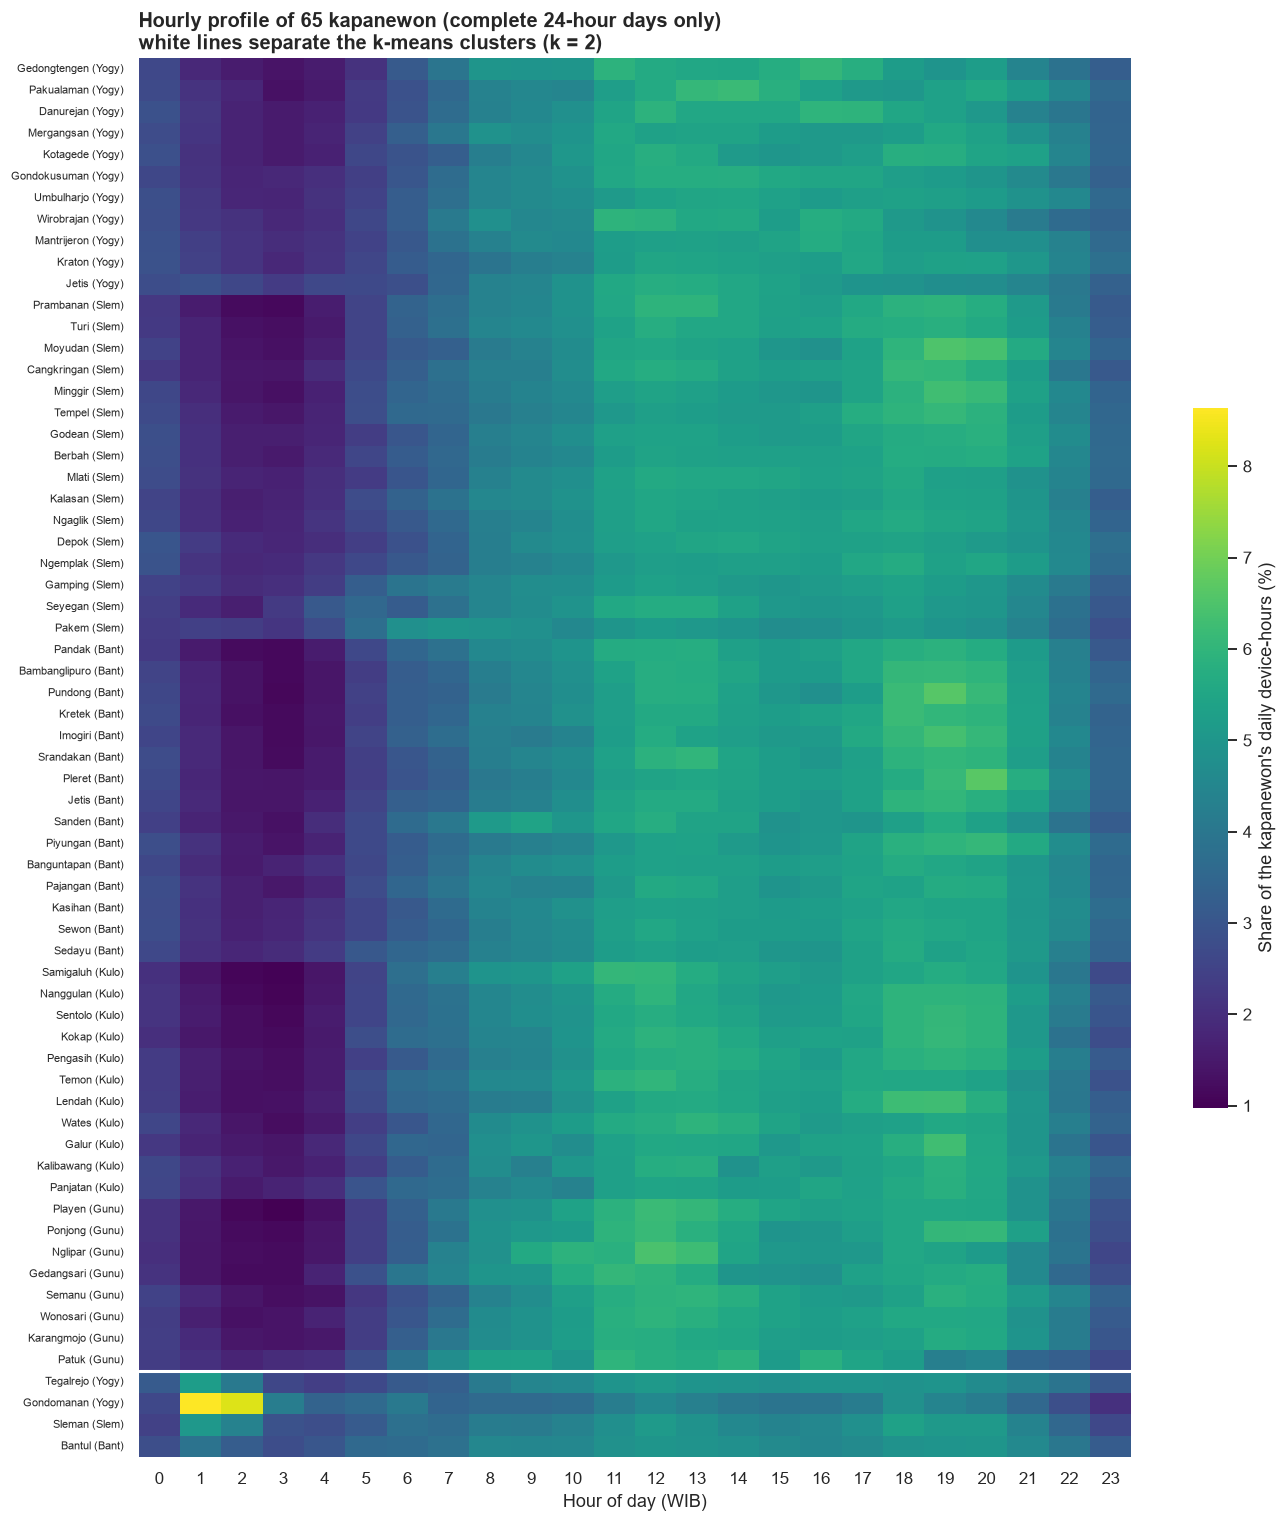

In [7]:
row_order = (pd.DataFrame({"cluster": cluster, "kab": pd.Categorical(kab_of, KAB_ORDER), "night": night_share})
             .sort_values(["cluster", "kab", "night"]).index)
mat = prof_pct.loc[row_order]

fig, ax = plt.subplots(figsize=(12.8, 14))
sns.heatmap(mat, ax=ax, cmap="viridis", cbar_kws={"label": "Share of the kapanewon's daily device-hours (%)", "shrink": .5})
labels = [f"{names.kapanewon[c].title()} ({names.kab_kota[c].title()[:4]})" for c in mat.index]
ax.set_yticks(np.arange(len(mat)) + .5, labels, fontsize=7)
for c in sorted(cluster.unique())[1:]:
    ax.axhline((cluster.loc[row_order] < c).sum(), color="white", lw=2)
ax.set_xlabel("Hour of day (WIB)")
ax.set_ylabel("")
ax.set_title(f"Hourly profile of {len(mat)} kapanewon (complete 24-hour days only)\n"
             f"white lines separate the k-means clusters (k = {K})", loc="left")
fig.tight_layout()
savefig(fig, "hour_kapanewon_heatmap")

## 4. F9: weekdays vs days off

For each kapanewon, the mean profile on working days and on days off (weekends and holidays), both from complete days only. The difference is in percentage points of the day.

In [8]:
by_type = kapanewon_profiles(hourly, by=["is_day_off"])
n_days_type = full.groupby(["kapanewon_code", "is_day_off"]).date.nunique().unstack()
both = n_days_type.index[(n_days_type >= 5).all(axis=1)]
diff = by_type.xs(True, level="is_day_off").loc[both] - by_type.xs(False, level="is_day_off").loc[both]
print(f"Kapanewon with >= 5 complete days of each type: {len(both)}")

kab_both = names.loc[both, "kab_kota"]
diff_kab = diff.groupby(kab_both).mean().reindex(KAB_ORDER)
blocks = {"night 00-05": range(0, 6), "morning 06-08": range(6, 9), "day 09-17": range(9, 18),
          "evening 18-23": range(18, 24)}
diff_tbl = pd.DataFrame({b: diff_kab[list(h)].sum(axis=1) for b, h in blocks.items()}).round(2)
print("Day off minus weekday, percentage points of the day (mean over kapanewon):")
display(diff_tbl)

Kapanewon with >= 5 complete days of each type: 65
Day off minus weekday, percentage points of the day (mean over kapanewon):


,night 00-05,morning 06-08,day 09-17,evening 18-23
kab_kota,,,,
YOGYAKARTA,2.24,-0.53,-2.68,0.98
SLEMAN,1.63,-0.28,-1.40,0.04
BANTUL,1.69,0.01,-1.13,-0.56
KULON PROGO,0.89,-0.16,-1.08,0.35
GUNUNGKIDUL,0.82,-0.39,-1.60,1.17


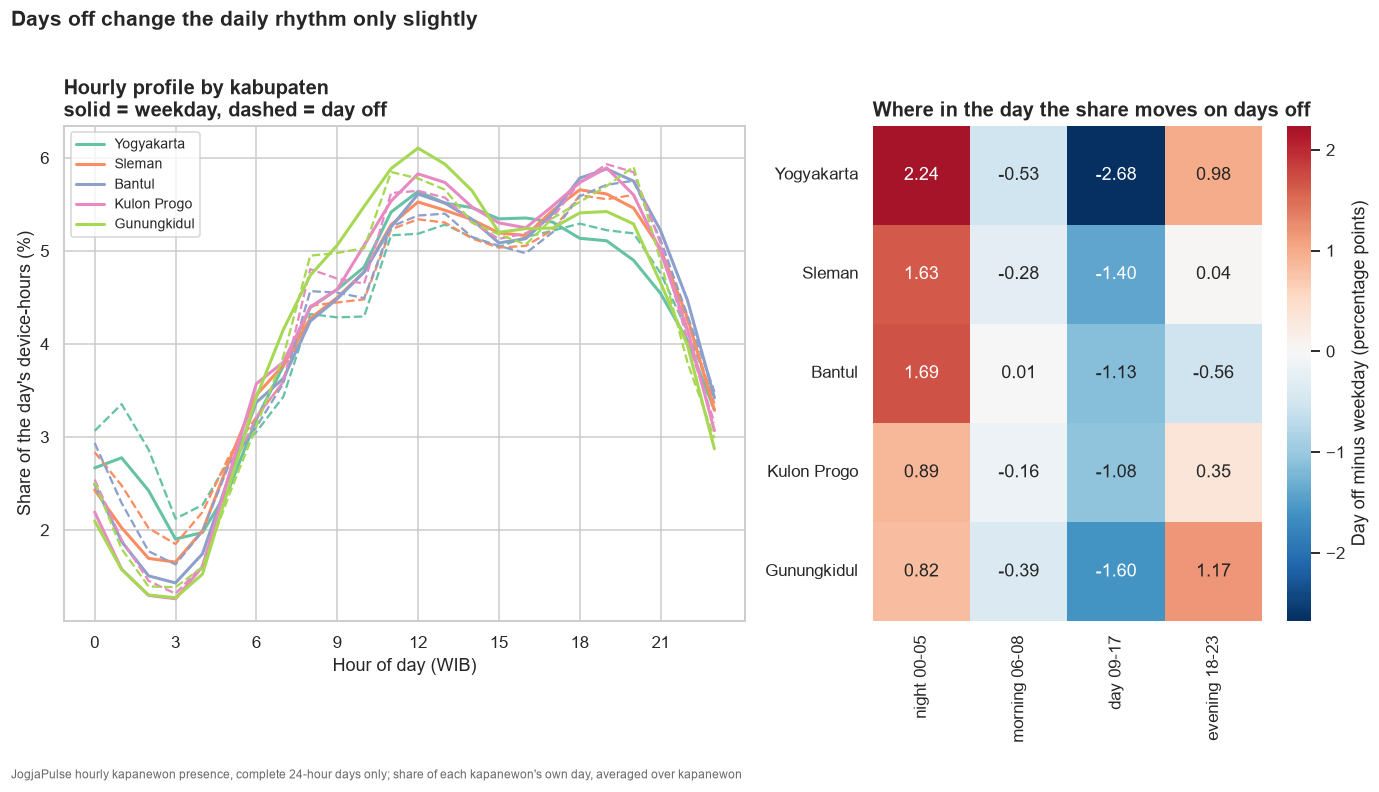

In [9]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
wk = by_type.xs(False, level="is_day_off").loc[both].groupby(kab_both).mean()
off = by_type.xs(True, level="is_day_off").loc[both].groupby(kab_both).mean()
for kab in KAB_ORDER:
    ax.plot(wk.columns, wk.loc[kab], color=KAB_COL[kab], lw=2, label=kab.title())
    ax.plot(off.columns, off.loc[kab], color=KAB_COL[kab], lw=1.5, ls="--")
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of day (WIB)")
ax.set_ylabel("Share of the day's device-hours (%)")
ax.set_title("Hourly profile by kabupaten\nsolid = weekday, dashed = day off", loc="left")
ax.legend(fontsize=9)

ax = axes[1]
sns.heatmap(diff_tbl, ax=ax, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "Day off minus weekday (percentage points)"})
ax.set_yticklabels([k.title() for k in diff_tbl.index], rotation=0)
ax.set_ylabel("")
ax.set_title("Where in the day the share moves on days off", loc="left")
fig.suptitle("Days off change the daily rhythm only slightly", x=.01, ha="left", fontweight="bold", fontsize=14)
fig.text(.01, .01, "JogjaPulse hourly kapanewon presence, complete 24-hour days only; "
         "share of each kapanewon's own day, averaged over kapanewon", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, .97))
savefig(fig, "weekday_vs_dayoff")

## 5. Summary numbers for the script

In [10]:
big = summary.loc[0]
print(f"Kapanewon profiled: {len(keep)} of {N_KAPANEWON}; dropped {len(dropped)} "
      f"({dropped.kab_kota.value_counts().to_dict()}) for too few complete days")
print(f"Silhouette by k: { {k: round(v, 2) for k, v in scores.items()} }; chosen k = {K}")
print(f"Largest cluster: {int(big.kapanewon)} kapanewon, night {big['night 00-05 (%)']}%, "
      f"day {big['day 09-17 (%)']}%, evening {big['evening 18-21 (%)']}%")
for c in summary.index[1:]:
    members = ", ".join(names.loc[cluster.index[cluster == c], "kapanewon"].str.title())
    print(f"Cluster {c} ({int(summary.loc[c, 'kapanewon'])}): {members}; night {summary.loc[c, 'night 00-05 (%)']}%")
print(f"Night share vs devices per day: Spearman {r_night_size:.2f}")
print(f"Lowest hour of the mean profile: {diy_profile.idxmin():02d}:00 ({diy_profile.min():.2f}%), "
      f"highest: {diy_profile.idxmax():02d}:00 ({diy_profile.max():.2f}%)")
print("Largest day-off shift (pp):", diff_tbl.abs().stack().idxmax(), f"{diff_tbl.stack().loc[diff_tbl.abs().stack().idxmax()]:+.2f}")

Kapanewon profiled: 65 of 78; dropped 13 ({'GUNUNGKIDUL': 10, 'YOGYAKARTA': 1, 'BANTUL': 1, 'KULON PROGO': 1}) for too few complete days
Silhouette by k: {2: 0.67, 3: 0.52, 4: 0.25, 5: 0.22}; chosen k = 2
Largest cluster: 61 kapanewon, night 11.9%, day 47.4%, evening 21.8%
Cluster 1 (4): Bantul, Sleman, Tegalrejo, Gondomanan; night 22.7%
Night share vs devices per day: Spearman 0.36
Lowest hour of the mean profile: 03:00 (1.59%), highest: 12:00 (5.61%)
Largest day-off shift (pp): ('YOGYAKARTA', 'day 09-17') -2.68


Interpretation (wording follows the numbers printed above):

- 65 of 78 kapanewon have enough complete 24-hour days to profile. 10 of the 13 left out are in Gunungkidul, mostly in the south, so the most rural area is the least covered.
- The profiles are very similar. The silhouette score is highest at k = 2 (0.67), but that split only separates 4 kapanewon (Bantul, Sleman, Tegalrejo, Gondomanan) with a peak around 01:00-02:00; their night share is 22.7% against 11.9% for the other 61. Larger k only splits off more small groups (silhouette 0.25 at k = 4). There is no clear urban/rural cluster.
- The urban/rural difference is a small gradient: median night share (00-05) is 13.2% in Kota Yogyakarta and 10.5% in Gunungkidul; daytime share (09-17) is 46.9% and 49.0%. Night share also rises with devices per day (Spearman 0.36), so part of this gradient may come from panel size rather than place.
- The 01:00-02:00 peak in the 4 kapanewon is likely a small group of devices active at night (night counts in Gondomanan vary strongly from day to day). Not checked further.
- On days off, share moves from daytime to night in every kabupaten. The shift is largest in Kota Yogyakarta (daytime -2.68 pp, night +2.24 pp). The 06-08 morning share barely changes, which fits notebook 02: JogjaPulse shows little weekday commuting rhythm.
- These are shapes of the day, not volumes. They describe devices, not people.